# Detecção de câncer e tecido de origem por metilação do DNA

**Disciplina:** Genômica Computacional · **Autor:** João Pedro Thurow Tomaszewski
**Artigo de referência:** Liu, M. C. et al. (2020). *Sensitive and specific multi-cancer detection and localization using methylation signatures in cell-free DNA*. Annals of Oncology, 31(6), 745–759.

Este notebook é a parte prática do trabalho (Parte III do enunciado). Ele é **reprodutível do zero**: baixa os dados públicos, monta a matriz amostra × feature, treina e avalia os classificadores e gera todas as figuras e tabelas usadas no relatório.

**Roteiro**
1. Registro de fontes, classes e validação
2. Contexto: o artigo e a escolha dos dados
3. **Experimento principal — tecido tumoral (TCGA, 6 tipos de câncer)**
   - 3.1 Dados e amostragem · 3.2 Exploração · 3.3 Pipeline e validação · 3.4 Tumor vs normal · 3.5 Tecido de origem · 3.6 Fluxo hierárquico · 3.7 CpGs mais importantes · 3.8 Auditoria de vazamento
4. **Tentativa documentada — plasma (GSE186575)**
5. Comparação tecido × plasma × artigo
6. Conclusões

> **Tempo de execução:** ~35–60 min no Colab gratuito (o download do TCGA, ~2,7 GB, leva parte disso). A auditoria (seção 3.8) pode ser desligada com `RODAR_AUDITORIA = False`.

## 1. Registro de fontes, classes e validação

| Item | **Experimento principal — TCGA (tecido)** | **Tentativa — GSE186575 (plasma)** |
|---|---|---|
| Fonte | UCSC Xena: `TCGA.{COAD,STAD,LUAD,LIHC,BRCA,KIRC}.sampleMap/HumanMethylation450.gz` + *probe map* `illuminaMethyl450_hg19_GPL16304_TCGAlegacy` | GEO: `GSE186575_DNA-Met_CPM_matrix_promoter.txt.gz` + `series_matrix`; anotação de genes Ensembl BioMart (GRCh38) |
| Tecnologia / medida | Illumina 450K (bissulfito) · *beta value* (0–1) por CpG | cfMeDIP-seq · CPM por promotor |
| Amostras | 1.290 amostras de 919 pacientes | 98 amostras (1 por pessoa) |
| Classes | **Etapa 1:** tumor primário (`01`) vs normal adjacente (`11`). **Etapa 2:** tecido de origem entre os tumores — cólon, estômago, pulmão, fígado, mama, rim | **Detecção:** câncer (colorretal + gástrico) vs saudável. **Origem:** colorretal vs gástrico |
| Validação | *Nested CV* com `StratifiedGroupKFold` **agrupado por paciente** (externa 5 folds, interna 3) | *Nested CV* estratificada (externa 5 folds × 3 repetições, interna 5) |
| Prevenção de vazamento | Seleção supervisionada **dentro** do `Pipeline`; amostras do mesmo paciente nunca em treino e teste ao mesmo tempo; auditoria (3.8) | Seleção supervisionada **dentro** do `Pipeline`; demonstração com rótulos aleatórios |
| Algoritmo | `SelectKBest(f_classif)` → Random Forest (500 árvores, `class_weight="balanced"`) | idem, com filtro de presença antes |

## 2. Contexto: o artigo e a escolha dos dados

**O que o artigo faz.** Liu et al. (2020) sequenciam, após conversão por bissulfito, ~1,1 milhão de CpGs do **DNA livre circulante (cfDNA)** do plasma de 6.689 participantes (estudos CCGA e STRIVE). Um classificador em duas etapas decide (i) se há câncer e (ii) qual o tecido de origem (TOO). Na validação, independente e cega, atingem **especificidade de 99,3%** e **acurácia de TOO de 93%**.

**Por que não usamos os dados do artigo.** CCGA/STRIVE são dados proprietários da GRAIL: o artigo não tem número de acesso público e o registro do STRIVE declara `ipdSharing: NO`.

**Datasets públicos avaliados (Parte II):**

| | GSE186575 | GSE81314 | **TCGA (Xena)** | GSE314062 | GSE275598 | GSE122126 |
|---|---|---|---|---|---|---|
| Material | Plasma | Plasma | **Tecido** | Plasma | Plasma | Plasma + células |
| Medida | cfMeDIP (5mC) | 5hmC | 450K (5mC) | Bissulfito direcionado | cfMeDIP | 450K/EPIC |
| Amostras | 98 | 64 úteis | ~100–900 por coorte | 5 | 93 | 59 |
| Classes | colorretal, gástrico, saudável | 7 cânceres + saudável | tumor vs normal por tipo | 3 pacientes | tumores cerebrais pediátricos | sepse, transplante |
| Situação | **tentado** (seção 4) | outra marca epigenética | **escolhido** (seção 3) | pequeno demais | fora do tema | sem câncer suficiente |

**Decisão.** Começamos pelo GSE186575, o mais parecido com o artigo (plasma + controles saudáveis). A detecção ficou no nível do acaso e o sinal estava dominado por lote técnico e idade (seção 4). Por isso o **experimento principal passou a ser o TCGA**: metilação de **tecido tumoral**, com muitas amostras, vários tipos de câncer e pacientes com tumor e normal pareados.

> O problema muda: deixa de ser *detecção no sangue* e passa a ser **classificação do tecido**. Isso é discutido como limitação e usado como contraste (seção 5).

### Configuração do ambiente

No Colab, o repositório é clonado (se `REPO_URL` estiver preenchido); localmente, a raiz é encontrada procurando o `PLANO_EXECUCAO.md`. Sem o repositório, o notebook cria as pastas e baixa tudo sozinho.

In [1]:
import sys, gzip, time, urllib.parse, urllib.request, warnings
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = ""  # opcional: URL do repositório no GitHub
if IN_COLAB and REPO_URL and not Path("GenomicaComputacional").exists():
    !git clone -q {REPO_URL}

def find_root():
    for p in [Path.cwd(), *Path.cwd().parents, Path("GenomicaComputacional").resolve()]:
        if (p / "PLANO_EXECUCAO.md").exists():
            return p
    return Path.cwd()

ROOT = find_root()
RAW, REF, PROC = ROOT / "data" / "raw", ROOT / "data" / "reference", ROOT / "data" / "processed"
TCGA = RAW / "tcga"
FIG, TAB = ROOT / "results" / "figures", ROOT / "results" / "tables"
for d in (RAW, REF, PROC, TCGA, FIG, TAB):
    d.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import (StratifiedGroupKFold, StratifiedKFold, RepeatedStratifiedKFold,
                                     GridSearchCV, cross_val_predict)
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve,
                             accuracy_score, precision_score, recall_score, f1_score)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
RODAR_AUDITORIA = True
print("raiz do projeto:", ROOT)

raiz do projeto: C:\Code\Faculdade\GenomicaComputacional


In [2]:
def baixar(url, dest):
    # baixa para .part e só renomeia no fim: se a conexão cair, não fica um arquivo cortado passando por completo
    if not dest.exists():
        print("baixando", dest.name, "...", flush=True)
        tmp = dest.with_name(dest.name + ".part")
        urllib.request.urlretrieve(url, tmp)
        tmp.rename(dest)
    return dest

def metricas_por_classe(y_true, y_pred, classes):
    # precisão, sensibilidade, especificidade e F1 de cada classe (um-contra-todos), a partir da matriz de confusão
    cm = confusion_matrix(y_true, y_pred, labels=classes)
    linhas = []
    for i, c in enumerate(classes):
        tp = cm[i, i]; fn = cm[i].sum() - tp; fp = cm[:, i].sum() - tp; tn = cm.sum() - tp - fn - fp
        prec = tp / (tp + fp) if tp + fp else 0; rec = tp / (tp + fn)
        linhas.append({"classe": c, "n": cm[i].sum(), "precisao": prec, "sensibilidade": rec,
                       "especificidade": tn / (tn + fp), "f1": 2 * prec * rec / (prec + rec) if prec + rec else 0})
    return pd.DataFrame(linhas).set_index("classe")

# 3. Experimento principal — tecido tumoral (TCGA)

## 3.1 Dados e amostragem

**Fonte:** UCSC Xena, um arquivo por tipo de câncer (o arquivo PanCan único tem 14 GB e não cabe no Colab gratuito).

**Medida:** *beta value* de cada CpG, entre 0 e 1 = fração das cópias de DNA metiladas naquele sítio. A química é a mesma do artigo (bissulfito), mas a leitura é por array (450K), e não por sequenciamento.

**Seis tecidos:** cólon (COAD), estômago (STAD), pulmão (LUAD), fígado (LIHC), mama (BRCA) e rim (KIRC). Escolhemos tipos frequentes, de órgãos diferentes, incluindo dois do trato gastrointestinal (cólon e estômago) como par "difícil", e que tivessem amostras normais.

**Código da amostra TCGA:** `TCGA-XX-YYYY-TT` → os 12 primeiros caracteres identificam o **paciente**; `TT` é o tipo (`01` = tumor primário, `11` = tecido normal adjacente).

In [3]:
XENA = "https://tcga-xena-hub.s3.us-east-1.amazonaws.com/download"
COORTES = {"COAD": "cólon", "STAD": "estômago", "LUAD": "pulmão", "LIHC": "fígado", "BRCA": "mama", "KIRC": "rim"}

probemap_path = baixar(f"{XENA}/probeMap%2FilluminaMethyl450_hg19_GPL16304_TCGAlegacy", TCGA / "probeMap_450k.tsv")
for c in COORTES:
    p = baixar(f"{XENA}/TCGA.{c}.sampleMap%2FHumanMethylation450.gz", TCGA / f"TCGA.{c}.HumanMethylation450.gz")
    print(f"{c}: {p.stat().st_size/1e6:.0f} MB")

COAD: 309 MB
STAD: 360 MB
LUAD: 450 MB
LIHC: 386 MB
BRCA: 783 MB
KIRC: 423 MB


**Amostragem (decisão D11).** Para equilibrar as classes e caber na memória do Colab:
- **todas** as amostras normais (`11`) — são a classe rara;
- os tumores **pareados** desses normais (mesmo paciente);
- tumores aleatórios até completar **150 por coorte** (sem isso, mama teria 790 tumores e dominaria a etapa 2).

**Pré-processamento:**
1. Só CpGs **autossômicos** (sai X/Y): mama é praticamente só feminina, e o modelo poderia aprender *sexo* em vez de *tecido*.
2. Remoção de CpGs com qualquer valor ausente (NaN).
3. Filtro **não supervisionado** (não usa rótulos): os **20 mil CpGs de maior variância**. A seleção *supervisionada* fica dentro da validação (3.3). A auditoria (3.8) mostra que aplicar esse filtro dentro de cada fold dá o mesmo resultado.

A leitura é feita em blocos de 50 mil linhas e em `float32` para economizar memória. A matriz completa fica em cache (`data/processed/`).

In [4]:
MAX_TUMOR = 150
pm = pd.read_csv(probemap_path, sep="\t", index_col=0)
probes_auto = set(pm.index[pm["chrom"].isin({f"chr{i}" for i in range(1, 23)})])
print(f"CpGs no array: {len(pm)} | autossômicos: {len(probes_auto)}")

def escolher_amostras(cols, rng):
    normais = [s for s in cols if s[13:15] == "11"]
    tumores = [s for s in cols if s[13:15] == "01"]
    pac_normais = {s[:12] for s in normais}
    pareados = [s for s in tumores if s[:12] in pac_normais]
    resto = [s for s in tumores if s[:12] not in pac_normais]
    n_extra = max(0, MAX_TUMOR - len(pareados))
    extra = list(rng.choice(resto, size=min(n_extra, len(resto)), replace=False))
    return normais + pareados + extra

def cabecalho(c):
    with gzip.open(TCGA / f"TCGA.{c}.HumanMethylation450.gz", "rt") as f:
        return f.readline().rstrip("\n").split("\t")[1:]

def ler_coorte(c, rng):
    sel = escolher_amostras(cabecalho(c), rng)
    blocos = [ch[ch.index.isin(probes_auto)]
              for ch in pd.read_csv(TCGA / f"TCGA.{c}.HumanMethylation450.gz", sep="\t", index_col=0,
                                    usecols=["sample"] + sel, dtype={s: np.float32 for s in sel}, chunksize=50_000)]
    return pd.concat(blocos)

CACHE = PROC / "tcga_6coortes_completa.parquet"   # salva CpGs nas linhas (poucas colunas = parquet rápido)
if CACHE.exists():
    M = pd.read_parquet(CACHE).T
else:
    rng = np.random.default_rng(RANDOM_STATE)
    mats = {}
    for c in COORTES:
        mats[c] = ler_coorte(c, rng); print(c, mats[c].shape, flush=True)
    M = pd.concat(mats.values(), axis=1, join="inner").T          # amostras x CpGs
    del mats
    print("matriz autossômica:", M.shape)
    nan = M.isna().any()
    print(f"CpGs com algum NaN (removidos): {nan.sum()}")
    M = M.loc[:, ~nan]
    M.T.to_parquet(CACHE)
print("matriz completa (sem NaN):", M.shape)

top20k = M.var().sort_values(ascending=False).index[:20_000]
X = M[top20k]
print("X (top 20 mil por variância):", X.shape)

CpGs no array: 395985 | autossômicos: 385809


COAD (385809, 188)


STAD (385809, 152)


LUAD (385809, 182)


LIHC (385809, 200)


BRCA (385809, 248)


KIRC (385809, 320)


matriz autossômica: (1290, 385809)
CpGs com algum NaN (removidos): 49549


matriz completa (sem NaN): (1290, 336260)


X (top 20 mil por variância): (1290, 20000)


In [5]:
origem = {s: c for c in COORTES for s in cabecalho(c)}
meta = pd.DataFrame(index=X.index)
meta["paciente"] = meta.index.str[:12]
meta["tipo"] = np.where(meta.index.str[13:15] == "11", "normal", "tumor")
meta["tecido"] = meta.index.map(origem).map(COORTES)
display(pd.crosstab(meta["tecido"], meta["tipo"], margins=True, margins_name="total"))
print("pacientes únicos:", meta["paciente"].nunique(), "| pacientes com tumor E normal:",
      (meta.groupby("paciente")["tipo"].nunique() == 2).sum())

tipo,normal,tumor,total
tecido,,,
cólon,38,150,188
estômago,2,150,152
fígado,50,150,200
mama,98,150,248
pulmão,32,150,182
rim,160,160,320
total,380,910,1290


pacientes únicos:

 919 | pacientes com tumor E normal: 371


**Observações sobre as classes:**
- São 1.290 amostras de 919 pacientes; **371 pacientes têm tumor e normal** — por isso a validação precisa ser agrupada por paciente (3.3).
- O **estômago tem só 2 normais** em todo o TCGA: a especificidade da etapa 1 nesse tecido não pode ser avaliada de forma confiável.
- O rim tem 160 tumores porque todos são pareados com normais (160 > 150).

## 3.2 Exploração: PCA

Se a metilação carrega a identidade do tecido, as amostras devem se agrupar por **tecido** e, dentro de cada tecido, separar **tumor** de **normal**. A PCA não usa rótulos: as cores são colocadas depois.

variância explicada (PC1..PC5): [0.347 0.116 0.07  0.047 0.031]


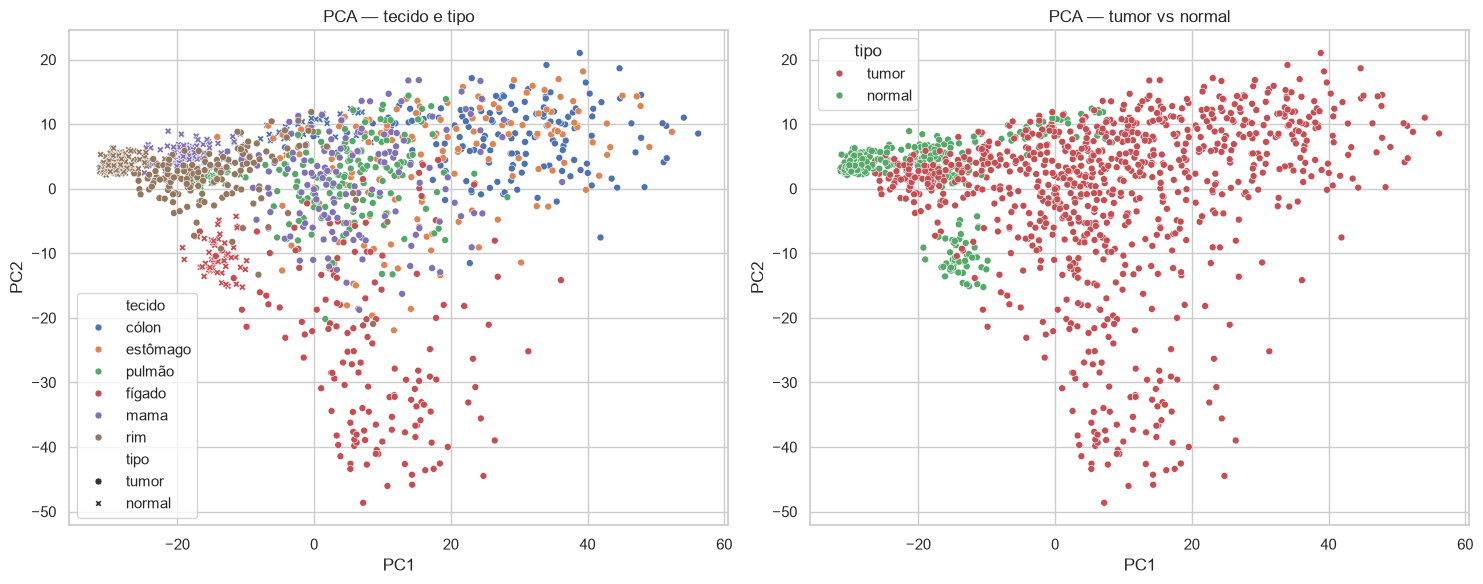

In [6]:
Z = X - X.mean()
pca = PCA(n_components=10, random_state=RANDOM_STATE).fit(Z)
pcs = pd.DataFrame(pca.transform(Z)[:, :2], index=X.index, columns=["PC1", "PC2"]).join(meta)
print("variância explicada (PC1..PC5):", pca.explained_variance_ratio_[:5].round(3))
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(data=pcs, x="PC1", y="PC2", hue="tecido", style="tipo", s=25, ax=ax[0]).set(title="PCA — tecido e tipo")
sns.scatterplot(data=pcs, x="PC1", y="PC2", hue="tipo", s=25, ax=ax[1], palette={"tumor": "C3", "normal": "C2"}).set(title="PCA — tumor vs normal")
plt.tight_layout(); plt.savefig(FIG / "tcga_pca.png", dpi=150); plt.show()

**Interpretação.** Os **normais formam grupos compactos por tecido** (rim, mama, pulmão e fígado bem separados): cada órgão tem um programa de metilação próprio. Os **tumores se espalham**, refletindo a heterogeneidade e a desregulação da metilação no câncer (hipometilação global, hipermetilação focal). O fígado tumoral forma um "braço" próprio. Ou seja: já sem nenhum modelo supervisionado, o sinal de tecido é visível.

## 3.3 Pipeline e validação

**Pipeline (`sklearn.Pipeline`):**
1. `SelectKBest(f_classif)` — teste F (ANOVA) entre as classes; mantém os *k* CpGs mais discriminativos. É **supervisionado** (usa os rótulos), então fica **dentro** do pipeline e é reajustado só com o treino de cada fold.
2. `RandomForestClassifier` — 500 árvores, `class_weight="balanced"` para compensar o desbalanceamento.

**Por que Random Forest:** lida bem com muito mais features do que amostras (p ≫ n), captura interações, não depende da escala das variáveis e fornece importância das features. O artigo usa regressão logística; a diferença é discutida no relatório.

**Validação aninhada (*nested CV*):**
- **externa** (5 folds): estima o desempenho — cada amostra é prevista uma única vez, por um modelo que nunca a viu;
- **interna** (3 folds, só dentro do treino externo): escolhe *k* ∈ {100, 500, 2000}.

**Agrupamento por paciente (`StratifiedGroupKFold`, grupo = paciente).** Tumor e normal do mesmo paciente **nunca** ficam um no treino e outro no teste. Sem isso, o modelo poderia acertar reconhecendo a metilação constitucional *do indivíduo*, e não o tumor — isso cumpre o item 9 do enunciado (separar indivíduos).

In [7]:
def make_pipeline(k=500):
    return Pipeline([("selecao", SelectKBest(f_classif, k=k)),
                     ("rf", RandomForestClassifier(n_estimators=500, class_weight="balanced",
                                                   random_state=RANDOM_STATE, n_jobs=-1))])

PARAM_GRID = {"selecao__k": [100, 500, 2000]}

def nested_cv(Xt, yt, groups, scoring):
    outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
    classes = sorted(yt.unique())
    pred = pd.Series(index=yt.index, dtype=object)
    prob = pd.DataFrame(index=yt.index, columns=classes, dtype=float)
    escolhas, cruzados = [], 0
    for tr, te in outer.split(Xt, yt, groups):
        cruzados += len(set(groups.iloc[tr]) & set(groups.iloc[te]))   # deve ser sempre 0
        s = GridSearchCV(make_pipeline(), PARAM_GRID, cv=inner, scoring=scoring, n_jobs=1)
        s.fit(Xt.iloc[tr], yt.iloc[tr], groups=groups.iloc[tr])
        pred.iloc[te] = s.predict(Xt.iloc[te]); prob.iloc[te] = s.predict_proba(Xt.iloc[te])
        escolhas.append(s.best_params_["selecao__k"])
    print("k escolhido em cada fold externo:", escolhas, "| pacientes em treino e teste ao mesmo tempo:", cruzados)
    return pred, prob

## 3.4 Etapa 1 — Tumor vs normal

Todas as 1.290 amostras. Classe positiva = tumor.

k escolhido em cada fold externo: [2000, 2000, 2000, 500, 2000] | pacientes em treino e teste ao mesmo tempo: 0
Acurácia: 0.984 | ROC-AUC: 0.997 | tempo: 52s


,n,precisao,sensibilidade,especificidade,f1
classe,,,,,
normal,380,0.969,0.979,0.987,0.974
tumor,910,0.991,0.987,0.979,0.989


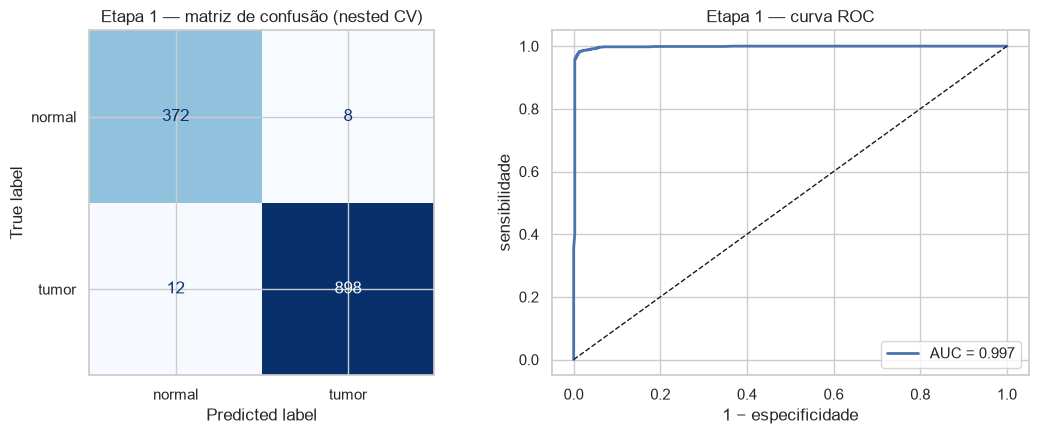

In [8]:
t0 = time.time()
y1, g1 = meta["tipo"], meta["paciente"]
pred1, prob1 = nested_cv(X, y1, g1, "roc_auc")
auc1 = roc_auc_score(y1 == "tumor", prob1["tumor"])
print(f"Acurácia: {accuracy_score(y1, pred1):.3f} | ROC-AUC: {auc1:.3f} | tempo: {time.time()-t0:.0f}s")
display(metricas_por_classe(y1, pred1, ["normal", "tumor"]).round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y1, pred1, labels=["normal", "tumor"]), display_labels=["normal", "tumor"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Etapa 1 — matriz de confusão (nested CV)")
fpr, tpr, _ = roc_curve(y1 == "tumor", prob1["tumor"])
ax[1].plot(fpr, tpr, lw=2, label=f"AUC = {auc1:.3f}"); ax[1].plot([0, 1], [0, 1], "k--", lw=1)
ax[1].set(xlabel="1 − especificidade", ylabel="sensibilidade", title="Etapa 1 — curva ROC"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG / "tcga_etapa1.png", dpi=150); plt.show()

In [9]:
# desempenho da etapa 1 dentro de cada tecido
d = pd.DataFrame({"tecido": meta["tecido"], "y": y1, "pred": pred1})
por_tecido = d.groupby("tecido").apply(lambda t: pd.Series({
    "n_normal": (t.y == "normal").sum(), "n_tumor": (t.y == "tumor").sum(),
    "sensibilidade": ((t.pred == "tumor") & (t.y == "tumor")).sum() / (t.y == "tumor").sum(),
    "especificidade": ((t.pred == "normal") & (t.y == "normal")).sum() / max((t.y == "normal").sum(), 1)}))
por_tecido.round(3)

,n_normal,n_tumor,sensibilidade,especificidade
tecido,,,,
cólon,38.0,150.0,1.000,0.921
estômago,2.0,150.0,0.993,0.000
fígado,50.0,150.0,0.967,0.960
mama,98.0,150.0,0.993,0.990
pulmão,32.0,150.0,0.987,1.000
rim,160.0,160.0,0.981,1.000


**Interpretação.** Acurácia ≈ 0,98 e AUC ≈ 0,997: a metilação separa tumor de normal quase perfeitamente em tecido. Por tecido, a sensibilidade fica ≥ 0,97 em todos. A especificidade do **estômago (0/2)** não tem valor estatístico — são só 2 normais. O cólon tem a menor especificidade entre os tecidos com normais suficientes (~0,92).

## 3.5 Etapa 2 — Tecido de origem (6 classes)

Só os 910 tumores. É o análogo, em tecido, da etapa de TOO do artigo. A métrica de escolha de *k* é o F1 macro (média simples entre as classes).

k escolhido em cada fold externo: [2000, 2000, 2000, 2000, 500] | pacientes em treino e teste ao mesmo tempo: 0
Acurácia: 0.980 | F1 macro: 0.980 | ROC-AUC macro (um-contra-todos): 0.999 | tempo: 50s


,n,precisao,sensibilidade,especificidade,f1
classe,,,,,
cólon,150,0.979,0.940,0.996,0.959
estômago,150,0.929,0.960,0.986,0.944
fígado,150,1.000,1.000,1.000,1.000
mama,150,0.987,1.000,0.997,0.993
pulmão,150,0.993,0.987,0.999,0.990
rim,160,0.994,0.994,0.999,0.994


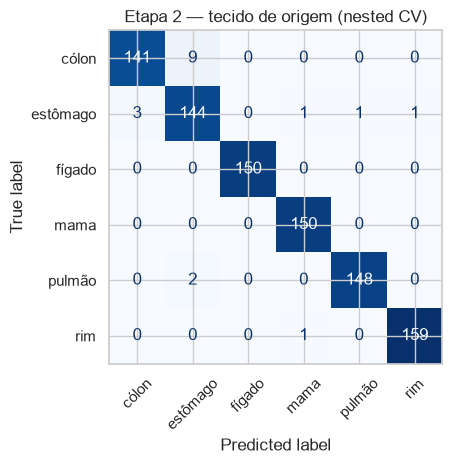

In [10]:
t0 = time.time()
tum = meta.index[meta["tipo"] == "tumor"]
y2, g2 = meta.loc[tum, "tecido"], meta.loc[tum, "paciente"]
pred2, prob2 = nested_cv(X.loc[tum], y2, g2, "f1_macro")
classes2 = sorted(y2.unique())
auc2 = roc_auc_score(y2, prob2[classes2], multi_class="ovr", average="macro")
print(f"Acurácia: {accuracy_score(y2, pred2):.3f} | F1 macro: {f1_score(y2, pred2, average='macro'):.3f} | "
      f"ROC-AUC macro (um-contra-todos): {auc2:.3f} | tempo: {time.time()-t0:.0f}s")
display(metricas_por_classe(y2, pred2, classes2).round(3))

ConfusionMatrixDisplay(confusion_matrix(y2, pred2, labels=classes2), display_labels=classes2).plot(cmap="Blues", colorbar=False, xticks_rotation=45)
plt.title("Etapa 2 — tecido de origem (nested CV)"); plt.tight_layout(); plt.savefig(FIG / "tcga_etapa2.png", dpi=150); plt.show()

**Interpretação.** Acurácia ≈ 0,98 com 6 classes. Fígado, mama, pulmão e rim ficam em ≥ 0,99. O ponto fraco é o par **cólon ↔ estômago**: ambos são epitélios do trato gastrointestinal, com origem embrionária comum (endoderma), e compartilham parte do programa de metilação. Isso aparece também nos marcadores (3.7).

## 3.6 Fluxo hierárquico (como no artigo)

Combina as predições fora da amostra das duas etapas: a etapa 1 decide tumor/normal e, para quem foi chamado de tumor, a etapa 2 atribui o tecido. Para os **normais erroneamente chamados de tumor** (não existem na etapa 2), o tecido é previsto por um modelo treinado em todos os tumores — esses normais nunca fizeram parte do treino desse modelo. Resultado: um classificador de 7 classes (normal + 6 tecidos).

Acurácia hierárquica (7 classes): 0.971


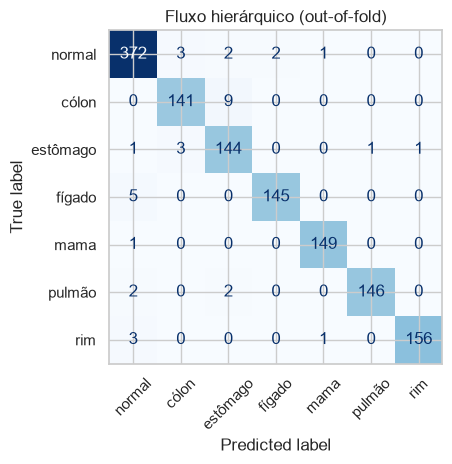

,n,precisao,sensibilidade,especificidade,f1
classe,,,,,
normal,380,0.969,0.979,0.987,0.974
cólon,150,0.959,0.940,0.995,0.949
estômago,150,0.917,0.960,0.989,0.938
fígado,150,0.986,0.967,0.998,0.976
mama,150,0.987,0.993,0.998,0.990
pulmão,150,0.993,0.973,0.999,0.983
rim,160,0.994,0.975,0.999,0.984


In [11]:
final = pd.Series("normal", index=X.index)
pos = pred1.index[pred1 == "tumor"]
pos_tumor = [s for s in pos if s in pred2.index]
final[pos_tumor] = pred2[pos_tumor]
fp_normais = [s for s in pos if s not in pred2.index]
if fp_normais:
    m2 = make_pipeline(k=500).fit(X.loc[tum], y2)
    final[fp_normais] = m2.predict(X.loc[fp_normais])
verdade = pd.Series(np.where(meta["tipo"] == "normal", "normal", meta["tecido"]), index=X.index)
ordem = ["normal"] + classes2
print(f"Acurácia hierárquica (7 classes): {accuracy_score(verdade, final):.3f}")
ConfusionMatrixDisplay(confusion_matrix(verdade, final, labels=ordem), display_labels=ordem).plot(cmap="Blues", colorbar=False, xticks_rotation=45)
plt.title("Fluxo hierárquico (out-of-fold)"); plt.tight_layout(); plt.savefig(FIG / "tcga_hierarquico.png", dpi=150); plt.show()
display(metricas_por_classe(verdade, final, ordem).round(3))

**Interpretação.** Acurácia ≈ 0,97 nas 7 classes. Os erros se dividem em: poucos normais chamados de tumor, poucos tumores chamados de normal (principalmente fígado) e a confusão **cólon → estômago**, que continua a maior.

## 3.7 Quais CpGs mais contribuem?

Para interpretar o modelo, ajustamos um modelo final em 75% dos pacientes (divisão agrupada) e medimos a **permutation importance** nos 25% restantes: embaralha um CpG por vez e mede quanto a acurácia cai. É mais confiável que a importância por impureza da própria floresta. Cada CpG é anotado com o gene mais próximo (probe map do Xena).

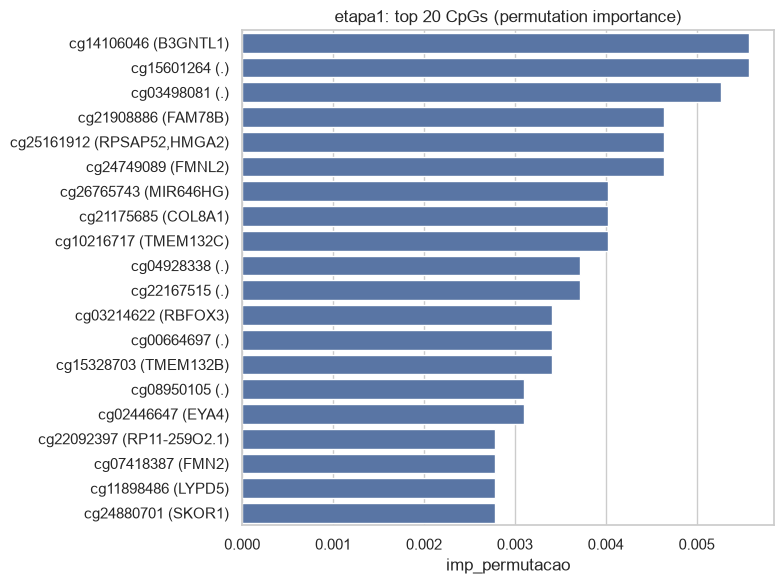

,cpg,imp_permutacao,imp_impureza,gene,chrom,chromStart
478,cg14106046,0.005573,0.023983,B3GNTL1,chr17,81006484
457,cg15601264,0.005573,0.009288,.,chr17,54864696
305,cg03498081,0.005263,0.018443,.,chr16,80061356
474,cg21908886,0.004644,0.007334,FAM78B,chr1,166039443
456,cg25161912,0.004644,0.010530,"RPSAP52,HMGA2",chr12,66220770
497,cg24749089,0.004644,0.024896,FMNL2,chr2,153322822
118,cg26765743,0.004025,0.028844,MIR646HG,chr20,59047487
383,cg21175685,0.004025,0.006244,COL8A1,chr3,99378031
176,cg10216717,0.004025,0.002674,TMEM132C,chr12,128899289
249,cg04928338,0.003715,0.012059,.,chr16,5286491


In [12]:
def importancias(Xt, yt, groups, tag, k=500, top=20):
    tr, te = next(StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE).split(Xt, yt, groups))
    m = make_pipeline(k=k).fit(Xt.iloc[tr], yt.iloc[tr])
    nomes = Xt.columns[m.named_steps["selecao"].get_support()]
    Xs = m.named_steps["selecao"].transform(Xt.iloc[te])
    pi = permutation_importance(m.named_steps["rf"], Xs, yt.iloc[te], n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
    imp = (pd.DataFrame({"cpg": nomes, "imp_permutacao": pi.importances_mean,
                         "imp_impureza": m.named_steps["rf"].feature_importances_})
             .join(pm[["gene", "chrom", "chromStart"]], on="cpg").sort_values("imp_permutacao", ascending=False))
    imp.to_csv(TAB / f"tcga_importancias_{tag}.csv", index=False)
    t = imp.head(top).assign(rotulo=lambda d: d["cpg"] + " (" + d["gene"].astype(str) + ")")
    plt.figure(figsize=(8, 6)); sns.barplot(data=t, y="rotulo", x="imp_permutacao", color="C0")
    plt.title(f"{tag}: top {top} CpGs (permutation importance)"); plt.ylabel(""); plt.tight_layout()
    plt.savefig(FIG / f"tcga_importancias_{tag}.png", dpi=150); plt.show()
    return imp

imp1 = importancias(X, y1, g1, "etapa1")
imp1.head(10)

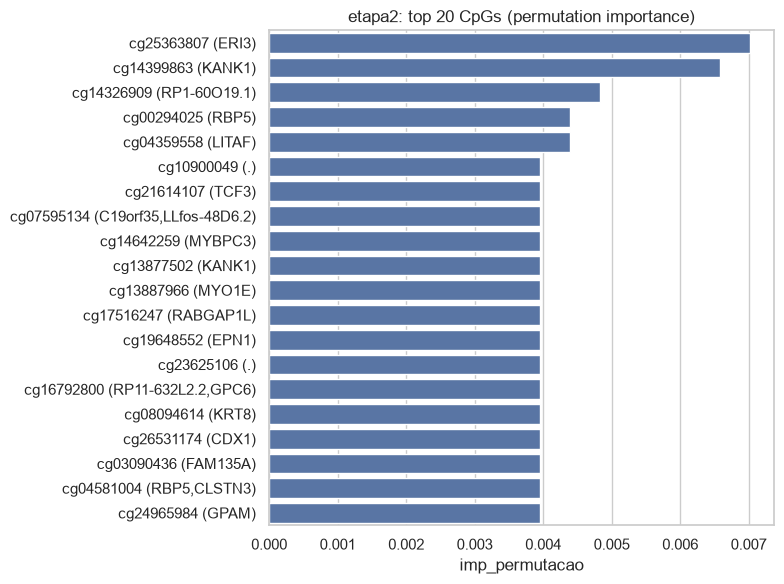

,cpg,imp_permutacao,imp_impureza,gene,chrom,chromStart
22,cg25363807,0.007018,0.008201,ERI3,chr1,44703922
338,cg14399863,0.006579,0.006414,KANK1,chr9,707165
250,cg14326909,0.004825,0.012868,RP1-60O19.1,chr6,107235622
173,cg00294025,0.004386,0.002066,RBP5,chr12,7276359
350,cg04359558,0.004386,0.007685,LITAF,chr16,11648223
25,cg10900049,0.003947,0.001993,.,chr2,8849961
497,cg21614107,0.003947,0.004136,TCF3,chr19,1633072
376,cg07595134,0.003947,0.001556,"C19orf35,LLfos-48D6.2",chr19,2278707
66,cg14642259,0.003947,0.000246,MYBPC3,chr11,47359016
83,cg13877502,0.003947,0.005224,KANK1,chr9,707386


In [13]:
imp2 = importancias(X.loc[tum], y2, g2, "etapa2")
imp2.head(10)

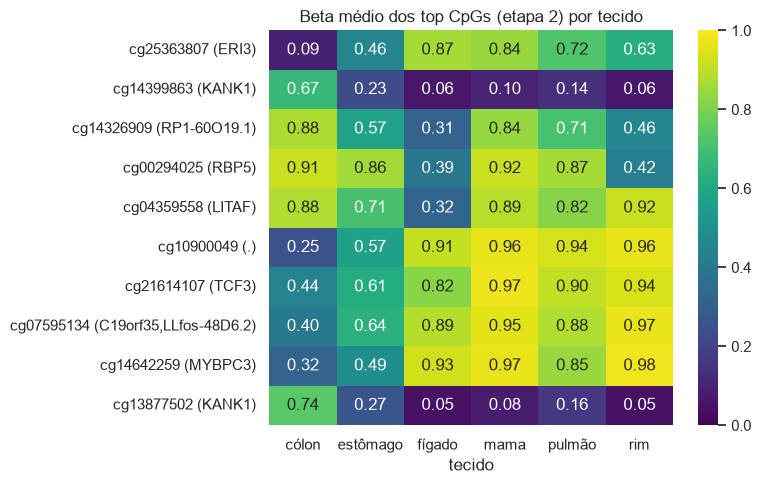

In [14]:
# beta médio dos 10 CpGs mais importantes da etapa 2, por tecido
top_cpgs = imp2["cpg"].head(10).tolist()
heat = X.loc[tum, top_cpgs].groupby(y2).mean().T
heat.index = [f"{c} ({pm.loc[c, 'gene']})" for c in heat.index]
plt.figure(figsize=(8, 5)); sns.heatmap(heat, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1)
plt.title("Beta médio dos top CpGs (etapa 2) por tecido"); plt.tight_layout()
plt.savefig(FIG / "tcga_heatmap_top_etapa2.png", dpi=150); plt.show()

**Interpretação do heatmap:**
- **KANK1** — metilado no cólon, intermediário no estômago, desmetilado nos demais: um **marcador de cólon**.
- **RBP5, LITAF** — **desmetilados no fígado** e altos nos outros tecidos: **marcadores de fígado**.
- **ERI3, TCF3** — baixos no cólon e altos nos demais.
- **O estômago fica "entre" o cólon e os outros tecidos**, o que explica a confusão cólon ↔ estômago.

Os valores de *permutation importance* são baixos (milésimos) porque há **muitos CpGs redundantes**: tirar um só não derruba o modelo. O sinal está espalhado pelo genoma — o que a auditoria a seguir confirma.

## 3.8 Auditoria de vazamento: o resultado não está bom demais?

Um desempenho de ~98% pede verificação. A auditoria testa cada caminho possível de vazamento e também se a tarefa é genuinamente fácil:

| Teste | O que verifica |
|---|---|
| Referência | Mesmo pipeline, CV agrupada simples (k = 500) |
| Integridade | IDs duplicados e pacientes cruzando treino/teste |
| Filtro de variância **dentro** de cada fold | Se o filtro não supervisionado feito antes da CV inflou o resultado |
| **20 mil CpGs aleatórios** | Se o sinal depende da escolha dos CpGs ou está espalhado |
| **Rótulos embaralhados** | Se o pipeline "inventa" sinal (deve dar AUC ≈ 0,5) |
| Árvore com 3 níveis / 1 único CpG | Se a tarefa é fácil a ponto de modelos triviais resolverem |

In [15]:
class TopVariance(BaseEstimator, TransformerMixin):
    # mesmo filtro de variância, mas ajustado só no treino de cada fold
    def __init__(self, n=20_000):
        self.n = n
    def fit(self, X, y=None):
        self.idx_ = np.argsort(np.asarray(X).var(axis=0))[::-1][: self.n]
        return self
    def transform(self, X):
        return np.asarray(X)[:, self.idx_]

def pipe_aud(pre=None, k=500, model=None):
    steps = ([("var", pre)] if pre is not None else []) + [
        ("sel", SelectKBest(f_classif, k=k)),
        ("clf", model or RandomForestClassifier(500, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1))]
    return Pipeline(steps)

cv_aud = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def avaliar(Xt, yt, gt, pipe):
    p = cross_val_predict(pipe, Xt, yt, groups=gt, cv=cv_aud, method="predict_proba")
    classes = sorted(yt.unique()); pred = np.array(classes)[p.argmax(1)]
    auc = roc_auc_score(yt == classes[1], p[:, 1]) if len(classes) == 2 else roc_auc_score(yt, p, multi_class="ovr")
    return {"acuracia": accuracy_score(yt, pred), "f1_macro": f1_score(yt, pred, average="macro"), "roc_auc": auc}

print("IDs duplicados:", M.index.duplicated().sum())
print("pacientes em treino e teste do mesmo fold:",
      sum(len(set(g1.iloc[tr]) & set(g1.iloc[te])) for tr, te in cv_aud.split(M, y1, g1)))

IDs duplicados: 0
pacientes em treino e teste do mesmo fold: 0


In [16]:
if RODAR_AUDITORIA:
    t0 = time.time()
    aleat = M.columns[np.random.default_rng(RANDOM_STATE).choice(M.shape[1], 20_000, replace=False)]
    arvore = lambda d: DecisionTreeClassifier(max_depth=d, class_weight="balanced", random_state=RANDOM_STATE)
    linhas = []
    for etapa, Mt, yt, gt in [("1: tumor vs normal", M, y1, g1), ("2: tecido de origem", M.loc[tum], y2, g2)]:
        y_perm = pd.Series(np.random.default_rng(RANDOM_STATE).permutation(yt.values), index=yt.index)
        testes = {
            "referência (top 20k global)":       (Mt[top20k], yt, pipe_aud()),
            "filtro de variância dentro do fold": (Mt, yt, pipe_aud(TopVariance(20_000))),
            "20 mil CpGs aleatórios":             (Mt[aleat], yt, pipe_aud()),
            "rótulos embaralhados":               (Mt[top20k], y_perm, pipe_aud()),
            "árvore de decisão com 3 níveis":     (Mt[top20k], yt, pipe_aud(model=arvore(3))),
            "1 único CpG + árvore de 1 nível":    (Mt[top20k], yt, pipe_aud(k=1, model=arvore(1))),
        }
        for nome, (Xa, ya, pipe) in testes.items():
            linhas.append({"etapa": etapa, "teste": nome, **avaliar(Xa, ya, gt, pipe)})
            print(f"etapa {etapa[:1]} · {nome} ok ({time.time()-t0:.0f}s)", flush=True)
    auditoria = pd.DataFrame(linhas).set_index(["etapa", "teste"]).round(3)
    auditoria.to_csv(TAB / "tcga_auditoria.csv")
    display(auditoria)

etapa 1 · referência (top 20k global) ok (6s)


etapa 1 · filtro de variância dentro do fold ok (14s)


etapa 1 · 20 mil CpGs aleatórios ok (20s)


etapa 1 · rótulos embaralhados ok (25s)


etapa 1 · árvore de decisão com 3 níveis ok (28s)


etapa 1 · 1 único CpG + árvore de 1 nível ok (30s)


... (3 outputs left out)

etapa 2 · rótulos embaralhados ok (54s)


etapa 2 · árvore de decisão com 3 níveis ok (56s)


etapa 2 · 1 único CpG + árvore de 1 nível ok (58s)


acuracia  f1_macro  \
etapa               teste                                                    
1: tumor vs normal  referência (top 20k global)            0.982     0.979   
                    filtro de variância dentro do fold     0.982     0.979   
                    20 mil CpGs aleatórios                 0.988     0.985   
                    rótulos embaralhados                   0.647     0.477   
                    árvore de decisão com 3 níveis         0.970     0.964   
                    1 único CpG + árvore de 1 nível        0.905     0.881   
2: tecido de origem referência (top 20k global)            0.978     0.978   
                    filtro de variância dentro do fold     0.977     0.977   
                    20 mil CpGs aleatórios                 0.980     0.980   
                    rótulos embaralhados                   0.180     0.177   
                    árvore de decisão com 3 níveis         0.647     0.550   
                    1 único CpG + árvore de 1 nível        0.331     0.233   

                                                        roc_auc  
etapa               teste                                        
1: tumor vs normal  referência (top 20k global)           0.997  
                    filtro de variância dentro do fold    0.997  
                    20 mil CpGs aleatórios                0.997  
                    rótulos embaralhados                  0.504  
                    árvore de decisão com 3 níveis        0.974  
                    1 único CpG + árvore de 1 nível       0.873  
2: tecido de origem referência (top 20k global)           0.999  
                    filtro de variância dentro do fold    0.999  
                    20 mil CpGs aleatórios                0.999  
                    rótulos embaralhados                  0.503  
                    árvore de decisão com 3 níveis        0.896  
                    1 único CpG + árvore de 1 nível       0.731

**Conclusão da auditoria:**
- **Nenhum vazamento:** 0 pacientes cruzando folds; filtro de variância dentro do fold dá o mesmo resultado; **rótulos embaralhados caem para AUC ≈ 0,50** (e acurácia ≈ 1/6 na etapa 2).
- **A tarefa é genuinamente fácil em tecido:** 20 mil CpGs **aleatórios** dão o mesmo desempenho, e **um único CpG** separa ~90% de tumor vs normal. O tecido tumoral é composto majoritariamente por DNA do tumor, e cada órgão tem um programa de metilação próprio (Hoadley et al., 2018).
- **Mas não é trivial em tudo:** a árvore com 3 níveis acerta só ~65% do tecido de origem — distinguir 6 tecidos exige combinar muitos CpGs.
- **Risco que não dá para testar:** lote/placa de processamento do TCGA confundido com o tipo de câncer (os IDs do Xena não trazem a placa). É mitigado pela coerência biológica (normais agrupados por tecido, marcadores tecido-específicos conhecidos) e entra como limitação.

**Por que fazer um experimento "fácil"?** (i) é fácil para o classificador, não para um humano — são centenas de milhares de valores por amostra; (ii) tem uso clínico real: **câncer de origem primária desconhecida** (3–5% dos cânceres), em que classificadores de metilação em tecido já são usados (EPICUP, Moran et al., 2016; tumores do SNC, Capper et al., 2018); (iii) funciona como **controle positivo** do pipeline — mostra que ele funciona quando o sinal existe, de modo que a falha no plasma (seção 4) pode ser atribuída aos dados, e não ao método; (iv) o próprio artigo usou arrays do TCGA para escolher as regiões do seu painel.

In [17]:
# libera a matriz completa antes da parte de plasma (memória do Colab)
del M, Z
import gc; gc.collect();

# 4. Tentativa documentada — plasma (GSE186575)

Este foi o **primeiro dataset escolhido**, por ser o mais próximo do artigo: **cfDNA do plasma** de pacientes com câncer colorretal (CRC, 32), gástrico (STAD, 35) e saudáveis (NC, 31), Peking University First Hospital. A detecção não funcionou, e esta seção documenta **por quê** — o que justifica a troca para o TCGA (decisão D10) e serve de contraste para a discussão.

**Dados:** cfMeDIP-seq (um anticorpo "pesca" os fragmentos metilados, que depois são sequenciados). A matriz pública é de **CPM por promotor** (fragmentos metilados por milhão) — um sinal agregado por gene, e não a fração de metilação por CpG. Uma amostra por pessoa, então não há risco de o mesmo indivíduo cair em treino e teste.

**Pré-processamento:**
- `log2(CPM + 1)` — transformação amostra a amostra (não usa estatística de outras amostras, logo pode ficar fora da CV);
- remoção de promotores de chrX, chrY, MT e sem anotação (decisão D6): na exploração, o **sexo dominava o 2º componente principal** e o grupo gástrico é 77% masculino — o modelo poderia separar gástrico de colorretal pelo sexo.

In [18]:
GEO = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE186nnn/GSE186575"
cpm_path = baixar(f"{GEO}/suppl/GSE186575_DNA-Met_CPM_matrix_promoter.txt.gz", RAW / "GSE186575_DNA-Met_CPM_matrix_promoter.txt.gz")
sm_path = baixar(f"{GEO}/matrix/GSE186575_series_matrix.txt.gz", RAW / "GSE186575_series_matrix.txt.gz")
ens_path = REF / "ensembl_genes_hg38.tsv"
if not ens_path.exists():   # anotação de genes (Ensembl BioMart, GRCh38); já vem no repositório
    q = ('<?xml version="1.0" encoding="UTF-8"?><!DOCTYPE Query><Query virtualSchemaName="default" formatter="TSV" header="1">'
         '<Dataset name="hsapiens_gene_ensembl" interface="default"><Attribute name="ensembl_gene_id"/>'
         '<Attribute name="external_gene_name"/><Attribute name="chromosome_name"/><Attribute name="gene_biotype"/></Dataset></Query>')
    baixar("https://www.ensembl.org/biomart/martservice?query=" + urllib.parse.quote(q), ens_path)

def read_geo_meta(path):
    rows = {}
    with gzip.open(path, "rt", encoding="utf-8") as f:
        for line in f:
            if line.startswith("!Sample_"):
                k, *v = line.rstrip("\n").split("\t")
                rows.setdefault(k, []).append([x.strip('"') for x in v])
    meta = pd.DataFrame({"title": rows["!Sample_title"][0]})
    for ch in rows["!Sample_characteristics_ch1"]:
        meta[ch[0].split(":")[0].strip().lower()] = [x.split(":", 1)[1].strip() for x in ch]
    return meta.set_index("title")

pmeta = read_geo_meta(sm_path)
pmeta["grupo"] = pmeta.index.str.split("-").str[0]
pmeta["lote_mix"] = pmeta.index.str.contains("mix")
pmeta["age"] = pd.to_numeric(pmeta["age"], errors="coerce")

cpm = pd.read_csv(cpm_path, sep="\t", index_col=0).T.loc[pmeta.index]
ann = pd.read_csv(ens_path, sep="\t").drop_duplicates("Gene stable ID").set_index("Gene stable ID")
gene_id = cpm.columns.str.replace("promoter_", "").str.split("|").str[0].str.split(".").str[0]
cromo = ann["Chromosome/scaffold name"].reindex(gene_id).values
Xp = np.log2(cpm.loc[:, np.isin(cromo, [str(i) for i in range(1, 23)])] + 1)
print("matriz original:", cpm.shape, "| após remover X/Y/MT/sem anotação:", Xp.shape)

matriz original: (98, 58288) | após remover X/Y/MT/sem anotação: (98, 53768)


### 4.1 Confundidores: lote e idade

Os nomes das amostras no GEO trazem o sufixo **"mix"** em quase todos os controles, mas raramente nos casos de câncer. O significado não está documentado; interpretamos como um **lote de processamento**. Os controles também são cerca de 10 anos mais jovens.

In [19]:
display(pd.crosstab(pmeta["grupo"], pmeta["lote_mix"].map({True: "mix", False: "não-mix"}), margins=True))
display(pmeta.groupby("grupo")["age"].describe()[["count", "mean", "50%", "min", "max"]].round(1))

lote_mix,mix,não-mix,All
grupo,,,
CRC,2,30,32
NC,25,6,31
STAD,0,35,35
All,27,71,98


,count,mean,50%,min,max
grupo,,,,,
CRC,32.0,60.7,62.5,42.0,83.0
NC,31.0,51.9,50.0,26.0,82.0
STAD,35.0,64.1,64.0,46.0,78.0


**Existe diferença de metilação entre as classes?** Teste F promotor a promotor, com correção de Benjamini–Hochberg (FDR 5%). Análise **descritiva**, fora do modelo. Comparamos com o contraste entre controles *mix* e *não-mix* — todos saudáveis, a única diferença é o lote.

In [20]:
def bh(p):
    # Benjamini–Hochberg: q-valores
    p = np.asarray(p); n = len(p); o = np.argsort(p)
    q = np.minimum.accumulate((p[o] * n / np.arange(1, n + 1))[::-1])[::-1]
    out = np.empty(n); out[o] = np.minimum(q, 1); return out

Lp = Xp.loc[:, (Xp > 0).mean() >= 0.5]   # promotores com sinal em pelo menos metade das amostras
grp, mix = pmeta["grupo"].values, pmeta["lote_mix"].values
contrastes = {"câncer vs saudável": (np.ones(len(grp), bool), grp != "NC"),
              "colorretal vs gástrico": (grp != "NC", grp == "STAD"),
              "saudável mix vs saudável não-mix (lote)": (grp == "NC", mix)}
fdr = {nome: int((bh(f_classif(Lp[m], y[m])[1]) < 0.05).sum()) for nome, (m, y) in contrastes.items()}
pd.Series(fdr, name="promotores com FDR < 5%").to_frame()

,promotores com FDR < 5%
câncer vs saudável,0
colorretal vs gástrico,0
saudável mix vs saudável não-mix (lote),526


**Resultado:** nenhum promotor difere significativamente entre câncer e saudável, nem entre colorretal e gástrico — mas centenas diferem entre controles *mix* e *não-mix*. **O lote deixa mais marca na metilação do que o câncer.**

### 4.2 Classificação (mesmo princípio do TCGA)

Pipeline: **filtro de presença** (promotor com sinal em ≥ 50% das amostras *de treino*) → `SelectKBest(f_classif)` → Random Forest. *Nested CV*: externa com 5 folds × 3 repetições (com n = 98, um único particionamento seria instável); interna com 5 folds escolhendo *k* ∈ {100, 500, 2000} e `max_features` ∈ {sqrt, 0,1}.

In [21]:
class PresenceFilter(BaseEstimator, TransformerMixin):
    # mantém promotores com valor > 0 em pelo menos min_frac das amostras de treino
    def __init__(self, min_frac=0.5):
        self.min_frac = min_frac
    def fit(self, X, y=None):
        self.mask_ = (np.asarray(X) > 0).mean(axis=0) >= self.min_frac
        return self
    def transform(self, X):
        return np.asarray(X)[:, self.mask_]

def pipe_plasma(k=500, max_features="sqrt"):
    return Pipeline([("filtro", PresenceFilter(0.5)), ("selecao", SelectKBest(f_classif, k=k)),
                     ("rf", RandomForestClassifier(n_estimators=500, max_features=max_features, class_weight="balanced",
                                                   random_state=RANDOM_STATE, n_jobs=-1))])

def nested_cv_plasma(Xt, yt):
    outer = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
    inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    grid = {"selecao__k": [100, 500, 2000], "rf__max_features": ["sqrt", 0.1]}
    res = []
    for tr, te in outer.split(Xt, yt):
        s = GridSearchCV(pipe_plasma(), grid, cv=inner, scoring="roc_auc", n_jobs=1).fit(Xt.iloc[tr], yt.iloc[tr])
        prob = s.predict_proba(Xt.iloc[te])[:, 1]; pred = (prob >= .5).astype(int)
        tn, fp, fn, tp = confusion_matrix(yt.iloc[te], pred, labels=[0, 1]).ravel()
        res.append({"acuracia": accuracy_score(yt.iloc[te], pred), "precisao": precision_score(yt.iloc[te], pred, zero_division=0),
                    "sensibilidade": tp / (tp + fn), "especificidade": tn / (tn + fp),
                    "f1": f1_score(yt.iloc[te], pred), "roc_auc": roc_auc_score(yt.iloc[te], prob)})
    return pd.DataFrame(res).agg(["mean", "std"]).T

t0 = time.time()
y_det = pd.Series((grp != "NC").astype(int), index=Xp.index)            # 1 = câncer
canc = Xp.index[grp != "NC"]
y_too = pd.Series((pmeta.loc[canc, "grupo"] == "STAD").astype(int))      # 1 = gástrico
res_plasma = pd.concat({"detecção (câncer vs saudável)": nested_cv_plasma(Xp, y_det),
                        "origem (colorretal vs gástrico)": nested_cv_plasma(Xp.loc[canc], y_too)}, axis=1).round(3)
res_plasma.to_csv(TAB / "metricas_nested_cv.csv")
print(f"tempo: {time.time()-t0:.0f}s"); res_plasma

tempo: 583s


detecção (câncer vs saudável)         \
                                        mean    std   
acuracia                               0.623  0.067   
precisao                               0.711  0.034   
sensibilidade                          0.763  0.145   
especificidade                         0.324  0.165   
f1                                     0.728  0.074   
roc_auc                                0.553  0.182   

               origem (colorretal vs gástrico)         
                                          mean    std  
acuracia                                 0.711  0.119  
precisao                                 0.729  0.143  
sensibilidade                            0.752  0.183  
especificidade                           0.663  0.191  
f1                                       0.726  0.122  
roc_auc                                  0.789  0.136

**Detecção no nível do acaso** (AUC ≈ 0,55) e especificidade muito baixa: quase todo mundo é chamado de câncer. A distinção **colorretal vs gástrico** tem algum sinal (AUC ≈ 0,79), mas fraco.

**O que o modelo de detecção está aprendendo?** Duas checagens com predições fora da amostra:
- Se ele aprendeu "lote mix ⇒ saudável", deve errar justamente os **saudáveis não-mix**.
- Um modelo que usa **só a idade** serve de linha de base.

In [22]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof = pd.Series(cross_val_predict(pipe_plasma(), Xp, y_det, cv=cv5, method="predict_proba")[:, 1], index=Xp.index)
tab = pmeta[["grupo", "lote_mix"]].assign(acertou=((oof >= .5).astype(int) == y_det))
display(tab.groupby(["grupo", "lote_mix"]).agg(n=("acertou", "size"), taxa_acerto=("acertou", "mean")).round(2))

rf_idade = RandomForestClassifier(n_estimators=500, min_samples_leaf=5, class_weight="balanced", random_state=RANDOM_STATE)
prob_idade = cross_val_predict(rf_idade, pmeta[["age"]], y_det, cv=cv5, method="predict_proba")[:, 1]
print(f"AUC da detecção — só idade: {roc_auc_score(y_det, prob_idade):.3f} | metilação: {roc_auc_score(y_det, oof):.3f}")

n  taxa_acerto
grupo lote_mix                 
CRC   False     30         0.63
      True       2         1.00
NC    False      6         0.00
      True      25         0.28
STAD  False     35         0.94

AUC da detecção — só idade: 0.703 | metilação: 0.526


**Leitura:** os saudáveis **não-mix** são todos chamados de câncer, e **a idade sozinha prevê "câncer" melhor do que a metilação**. Ou seja, o pouco que o modelo aprende na detecção é lote e idade, e não câncer. Por isso a correção de lote (ComBat) também não resolveria: o lote está quase alinhado à classe, e corrigi-lo removeria junto o que restasse de sinal (decisão D12).

### 4.3 Demonstração de vazamento

Para mostrar concretamente por que a seleção supervisionada precisa ficar dentro da validação, usamos **rótulos aleatórios** (não existe sinal real; o AUC honesto deveria ficar perto de 0,5):
- **errado:** seleciona os 500 promotores mais associados ao rótulo usando *todas* as amostras e só depois faz a CV;
- **certo:** seleção dentro do pipeline, reajustada em cada fold.

In [23]:
y_rand = pd.Series(np.random.default_rng(RANDOM_STATE).permutation(y_det.values), index=y_det.index)
sel = SelectKBest(f_classif, k=500).fit(Xp, y_rand)                        # ERRADO: vê o teste
rf = RandomForestClassifier(n_estimators=500, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
prob_errado = cross_val_predict(rf, Xp.loc[:, sel.get_support()], y_rand, cv=cv5, method="predict_proba")[:, 1]
prob_certo = cross_val_predict(pipe_plasma(), Xp, y_rand, cv=cv5, method="predict_proba")[:, 1]   # CERTO
print(f"Rótulos aleatórios — AUC COM vazamento: {roc_auc_score(y_rand, prob_errado):.3f}")
print(f"Rótulos aleatórios — AUC SEM vazamento: {roc_auc_score(y_rand, prob_certo):.3f}")

Rótulos aleatórios — AUC COM vazamento: 0.838
Rótulos aleatórios — AUC SEM vazamento: 0.265


Com vazamento, o modelo "encontra" sinal em rótulos que são puro ruído (AUC bem acima de 0,5). Sem vazamento, não há sinal espúrio — o valor abaixo de 0,5 é flutuação esperada com n pequeno. Toda a seleção supervisionada deste trabalho está dentro do pipeline.

### 4.4 Por que desistimos do plasma
Detecção no acaso, nenhum promotor significativo e um efeito de lote maior que o de câncer **não permitem um experimento de classificação viável**. A tentativa fica no trabalho como evidência de que detectar câncer no plasma é difícil — e exige a escala e a tecnologia do artigo.

# 5. Comparação tecido × plasma × artigo

| | Tecido (TCGA) | Plasma (GSE186575) | Artigo (Liu et al., 2020) |
|---|---|---|---|
| Material | Tumor | cfDNA | cfDNA |
| Fração de DNA tumoral | Alta (maior parte do DNA) | Em geral < 1% | Em geral < 1% |
| Tecnologia | Bissulfito, array 450K | Imunoprecipitação (MeDIP) | Bissulfito, sequenciamento direcionado |
| Resolução | CpG (~336 mil usados) | Promotor (~54 mil) | CpG em cada fragmento (~1,1 milhão) |
| n | 1.290 | 98 | 6.689 |
| Detecção | AUC 0,997 | AUC 0,55 | Especificidade 99,3% · sensibilidade 55% (I–IV) |
| Tecido de origem | Acurácia 0,98 (6 classes) | AUC 0,79 (2 classes) | Acurácia 93% (~20 sítios) |

**Mensagem:** a assinatura de metilação de cada tecido é forte **na fonte** — o tumor. No plasma, ela fica diluída no DNA das células do sangue e é facilmente superada por ruído técnico (lote) e por variáveis como a idade. O artigo vence essa distância com escala (milhares de participantes), profundidade de sequenciamento e leitura molécula a molécula.

# 6. Conclusões

1. **Em tecido, a metilação do DNA separa tumor de normal (AUC 0,997) e identifica o tecido de origem entre 6 tipos (acurácia 0,98)** com um Random Forest simples, validado por *nested CV* agrupada por paciente.
2. **O resultado não vem de vazamento:** rótulos embaralhados dão AUC 0,50, nenhum paciente cruza treino e teste, e o filtro de variância dentro dos folds não muda nada. A tarefa é fácil porque o sinal está espalhado por todo o genoma — 20 mil CpGs aleatórios bastam.
3. **Os CpGs mais importantes são tecido-específicos** (KANK1 no cólon; RBP5 e LITAF no fígado), e o estômago tem um perfil intermediário, o que explica a principal confusão (cólon ↔ estômago).
4. **No plasma, com dados públicos, a detecção falhou:** o sinal de lote e idade superou o de câncer. A seleção supervisionada fora da validação teria "fabricado" um AUC de ~0,84 a partir de rótulos aleatórios.
5. **Nada disso é um teste clínico:** tecido exige biópsia; o desenho é caso-controle com pacientes já diagnosticados; não há validação externa, cega e prospectiva; a especificidade não foi medida na escala necessária (≥ 99%); e há possíveis efeitos de lote não testáveis no TCGA.

As respostas completas às questões de discussão (11–16) estão no relatório técnico.